# Test paper "Near-Field and Far-Field Beamforming Design for RIS-enabled Millimeter Wave Systems" 

In [1]:
%matplotlib widget

import matplotlib.pyplot as plt
import numpy as np
import plotly.io as pio
from scipy.constants import c, pi

pio.renderers.default = (
    "notebook_connected"  # 'browser' for avoid error but shown in the browser
)

# import surpRISe
from surpRISe.channels.tx2ris2rx.tang_general_channel import tang_general_channel
from surpRISe.components.antenna import Antenna
from surpRISe.components.ris import RIS
from surpRISe.utils.utils import *

In [2]:
# Create TX antenna
tx_pos = np.array([5, 0, 5])  # x,y,z in meters
g_total = 1  # total gain in dB (TX + RIS + RX) --> TX gain = 0 dBi, RIS gain = 4*pi/(lam**2)*dx*dy = 1 dBi, RX gain = 0 dBi
tx_antenna = Antenna(position=tx_pos, gain_dbi=1)
tx_antenna.define_rad_pat(angles=np.arange(0, 360, 1), values=np.ones(360))  # isotropic

# Create RIS
lam = 5e-3  # 5 mm
f = c / lam
m = n = 50  # 50 elements per dimension
delta_h = delta_v = 0.5 * lam
# dx = dy = np.sqrt((10 ** 0.1) * (lam ** 2) / (4 * pi))  # to have 1 dBi gain
dx = dy = 0.5 * lam

ris = RIS(
    name="RIS",
    center=[0, 0, 0],
    boresight="z",
    Ncol=m,
    Nrow=n,
    delta_h=delta_h,
    delta_v=delta_v,
    dx=dx,
    dy=dy,
    fc=f,
    radiation_factor=0,
    phase_shifts_dict={"0": 0, "1": pi / 2, "2": pi, "3": -pi / 2},
    att_dict={"0": 1, "1": 1, "2": 1, "3": 1},
)

### Tests Algorithm 1 of the paper
Discrete phase shifts

Far-field distance border (pi/8) at theta=0.0º: 12.00 m
Far-field distance border (pi/8) at theta=30.0º: 10.47 m
Far-field distance border (pi/8) at theta=60.0º: 7.45 m
Far-field distance border (pi/4) at theta=0.0º: 6.00 m
Far-field distance border (pi/4) at theta=30.0º: 5.22 m
Far-field distance border (pi/4) at theta=60.0º: 3.70 m
Far-field distance border (pi/2) at theta=0.0º: 3.00 m
Far-field distance border (pi/2) at theta=30.0º: 2.59 m
Far-field distance border (pi/2) at theta=60.0º: 1.82 m


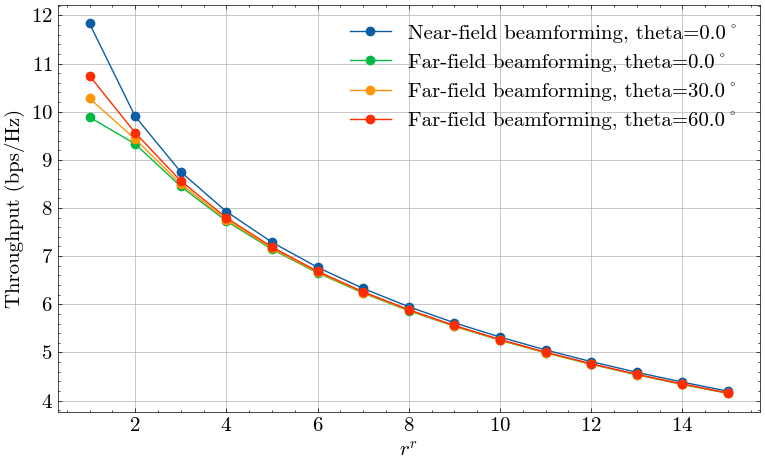

In [3]:
noise_pw = 1e-8  # W
p_tx = 10  # W

rx_phi = 180  # deg
rx_theta_rad_val = [0, pi / 6, pi / 3]  # rad
rx_theta_deg_val = np.degrees(rx_theta_rad_val)  # deg
rx_dist_val = np.arange(1, 16, 1)  # m

ff_border_0 = ris_ff_border(
    ris=ris, fc=f, phase_error_rad=pi / 8, phi_deg=rx_phi, theta_deg=rx_theta_deg_val[0]
)
ff_border_30 = ris_ff_border(
    ris=ris, fc=f, phase_error_rad=pi / 8, phi_deg=rx_phi, theta_deg=rx_theta_deg_val[1]
)
ff_border_60 = ris_ff_border(
    ris=ris, fc=f, phase_error_rad=pi / 8, phi_deg=rx_phi, theta_deg=rx_theta_deg_val[2]
)

ff_border_0_pi4 = ris_ff_border(
    ris=ris, fc=f, phase_error_rad=pi / 4, phi_deg=rx_phi, theta_deg=rx_theta_deg_val[0]
)
ff_border_30_pi4 = ris_ff_border(
    ris=ris, fc=f, phase_error_rad=pi / 4, phi_deg=rx_phi, theta_deg=rx_theta_deg_val[1]
)
ff_border_60_pi4 = ris_ff_border(
    ris=ris, fc=f, phase_error_rad=pi / 4, phi_deg=rx_phi, theta_deg=rx_theta_deg_val[2]
)

ff_border_0_pi2 = ris_ff_border(
    ris=ris, fc=f, phase_error_rad=pi / 2, phi_deg=rx_phi, theta_deg=rx_theta_deg_val[0]
)
ff_border_30_pi2 = ris_ff_border(
    ris=ris, fc=f, phase_error_rad=pi / 2, phi_deg=rx_phi, theta_deg=rx_theta_deg_val[1]
)
ff_border_60_pi2 = ris_ff_border(
    ris=ris, fc=f, phase_error_rad=pi / 2, phi_deg=rx_phi, theta_deg=rx_theta_deg_val[2]
)

print(
    f"Far-field distance border (pi/8) at theta={rx_theta_deg_val[0]}º: {ff_border_0:.2f} m"
)
print(
    f"Far-field distance border (pi/8) at theta={np.round(rx_theta_deg_val[1])}º: {ff_border_30:.2f} m"
)
print(
    f"Far-field distance border (pi/8) at theta={np.round(rx_theta_deg_val[2])}º: {ff_border_60:.2f} m"
)

print(
    f"Far-field distance border (pi/4) at theta={rx_theta_deg_val[0]}º: {ff_border_0_pi4:.2f} m"
)
print(
    f"Far-field distance border (pi/4) at theta={np.round(rx_theta_deg_val[1])}º: {ff_border_30_pi4:.2f} m"
)
print(
    f"Far-field distance border (pi/4) at theta={np.round(rx_theta_deg_val[2])}º: {ff_border_60_pi4:.2f} m"
)

print(
    f"Far-field distance border (pi/2) at theta={rx_theta_deg_val[0]}º: {ff_border_0_pi2:.2f} m"
)
print(
    f"Far-field distance border (pi/2) at theta={np.round(rx_theta_deg_val[1])}º: {ff_border_30_pi2:.2f} m"
)
print(
    f"Far-field distance border (pi/2) at theta={np.round(rx_theta_deg_val[2])}º: {ff_border_60_pi2:.2f} m"
)

ch_gen = tang_general_channel()

th_gen = np.zeros(
    (len(rx_theta_deg_val), len(rx_dist_val))
)  # throughput (bps/Hz) (Spetral Efficienecy)
th_ff = th_gen.copy()

for rx_theta_idx, rx_theta_deg in enumerate(rx_theta_deg_val):
    for rx_idx, rx_dist in enumerate(rx_dist_val):
        rx_pos = sph2cart([rx_dist, rx_phi, rx_theta_deg])
        rx_antenna = Antenna(position=rx_pos, gain_dbi=20)
        tx_antenna.define_rad_pat(
            angles=np.arange(0, 360, 1), values=np.ones(360)
        )  # isotropic

        # Spherical wave - Near-field beamforming
        ris.reset_ris()
        ch_gen.optimize(
            optimizer="direct_disc",
            mode="cont",
            wave_model="spherical",
            tx_antenna=tx_antenna,
            rx_antenna=rx_antenna,
            ris=ris,
        )
        pg_gen = ch_gen.path_gain_multrx(
            tx_antenna=tx_antenna, rx_antenna=rx_antenna, rx_positions=rx_pos, ris=ris
        )

        # Plane wove model (Far-field beamforming)
        ris.reset_ris()
        ch_gen.optimize(
            optimizer="direct_disc",
            mode="cont",
            wave_model="plane",
            tx_antenna=tx_antenna,
            rx_antenna=rx_antenna,
            ris=ris,
        )
        pg_ff = ch_gen.path_gain_multrx(
            tx_antenna=tx_antenna, rx_antenna=rx_antenna, rx_positions=rx_pos, ris=ris
        )

        th_gen[rx_theta_idx, rx_idx] = np.log2(1 + p_tx * pg_gen[0] / noise_pw)
        th_ff[rx_theta_idx, rx_idx] = np.log2(1 + p_tx * pg_ff[0] / noise_pw)


plt.figure(figsize=(8, 5))

plt.plot(
    rx_dist_val,
    th_gen[0, :],
    label=f"Near-field beamforming, theta={rx_theta_deg_val[0]}º",
    marker="o",
)
plt.plot(
    rx_dist_val,
    th_ff[0, :],
    label=f"Far-field beamforming, theta={rx_theta_deg_val[0]}º",
    marker="o",
)
# plt.plot(rx_dist_val, th_gen[1, :], label=f'Near-field beamforming, theta={np.round(rx_theta_deg_val[1])}º', marker='o')
plt.plot(
    rx_dist_val,
    th_ff[1, :],
    label=f"Far-field beamforming, theta={np.round(rx_theta_deg_val[1])}º",
    marker="o",
)
# plt.plot(rx_dist_val, th_gen[2, :], label=f'Near-field beamforming, theta={np.round(rx_theta_deg_val[2])}º', marker='o')
plt.plot(
    rx_dist_val,
    th_ff[2, :],
    label=f"Far-field beamforming, theta={np.round(rx_theta_deg_val[2])}º",
    marker="o",
)

plt.xlabel("$r^r$")
plt.ylabel("Throughput (bps/Hz)")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

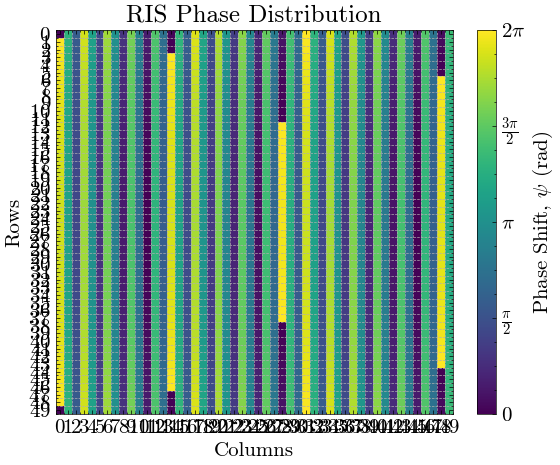

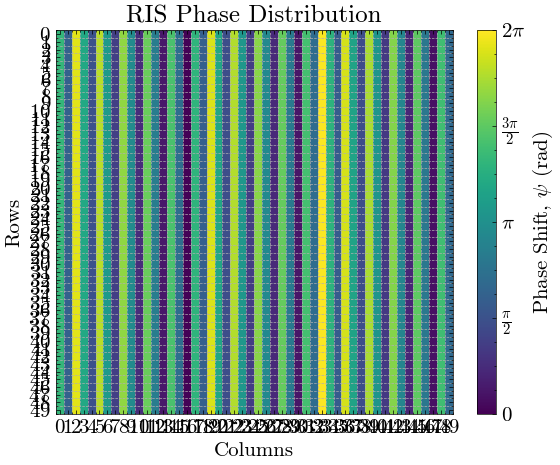

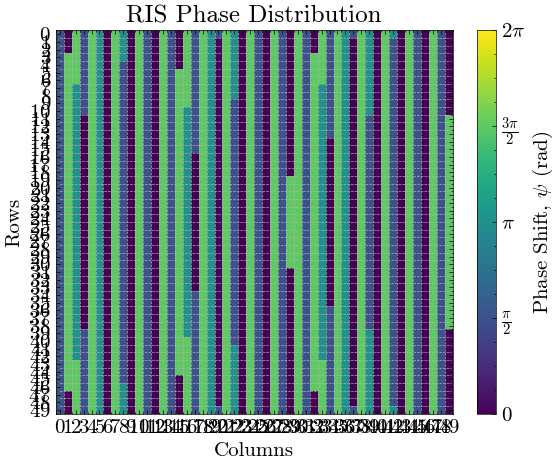

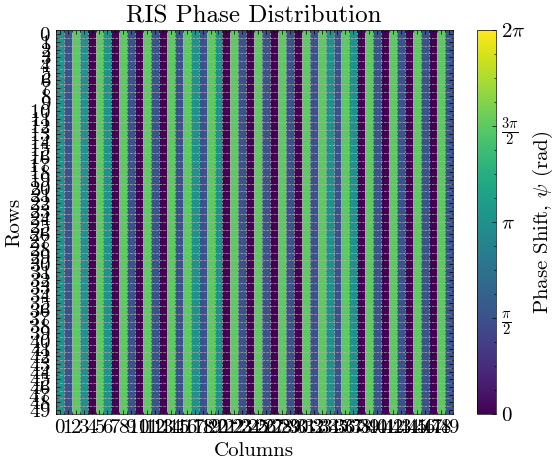

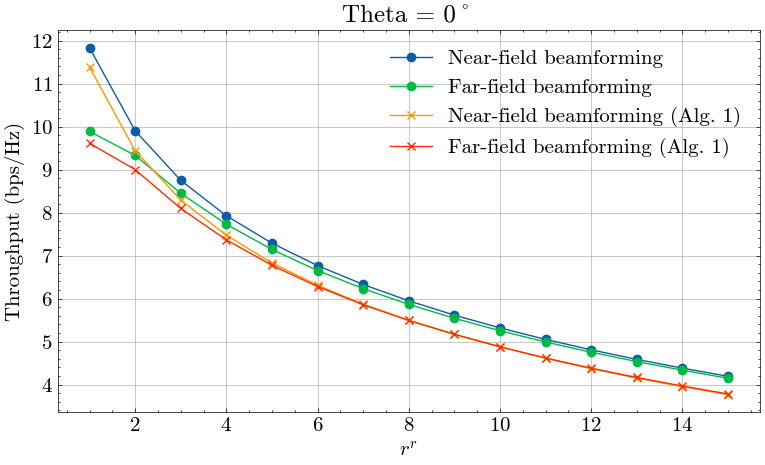

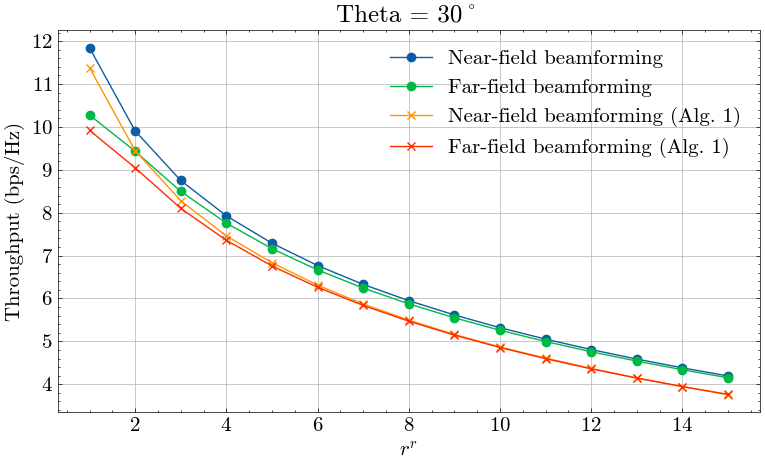

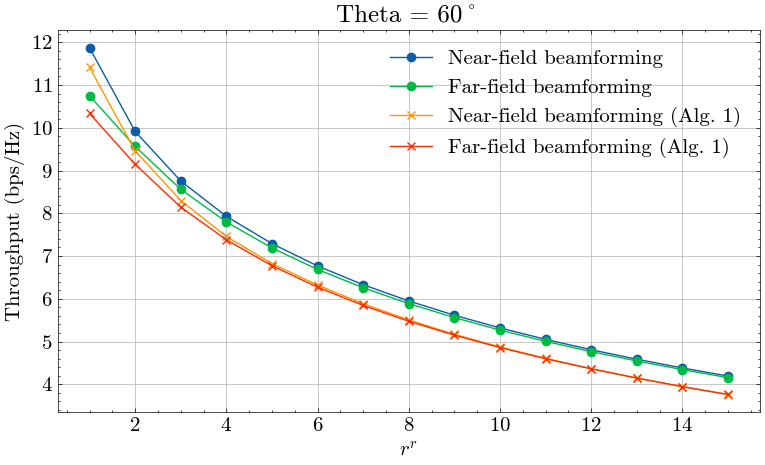

In [4]:
noise_pw = 1e-8  # W
p_tx = 10  # W

rx_phi = 180  # deg
rx_theta_rad_val = [0, pi / 6, pi / 3]  # rad
rx_theta_deg_val = np.degrees(rx_theta_rad_val)  # deg
rx_dist_val = np.arange(1, 16, 1)  # m

ch_gen = tang_general_channel()

th_gen = np.zeros(
    (len(rx_theta_deg_val), len(rx_dist_val))
)  # throughput (bps/Hz) (Spetral Efficienecy)
th_ff = th_gen.copy()
th_gen_disc = th_gen.copy()
th_ff_disc = th_gen.copy()

for rx_theta_idx, rx_theta_deg in enumerate(rx_theta_deg_val):
    for rx_idx, rx_dist in enumerate(rx_dist_val):
        rx_pos = sph2cart([rx_dist, rx_phi, rx_theta_deg])
        rx_antenna = Antenna(position=rx_pos, gain_dbi=20)
        tx_antenna.define_rad_pat(
            angles=np.arange(0, 360, 1), values=np.ones(360)
        )  # isotropic

        # Spherical wave - Near-field beamforming
        ris.reset_ris()
        ch_gen.optimize(
            mode="cont",
            wave_model="spherical",
            tx_antenna=tx_antenna,
            rx_antenna=rx_antenna,
            ris=ris,
        )
        pg_gen = ch_gen.path_gain_multrx(
            tx_antenna=tx_antenna, rx_antenna=rx_antenna, rx_positions=rx_pos, ris=ris
        )

        if rx_theta_idx == 0 and rx_idx == len(rx_dist_val) - 1:
            ris.plot_phase_dist()

        # Plane wove model (Far-field beamforming)
        ris.reset_ris()
        ch_gen.optimize(
            mode="cont",
            wave_model="plane",
            tx_antenna=tx_antenna,
            rx_antenna=rx_antenna,
            ris=ris,
        )
        pg_ff = ch_gen.path_gain_multrx(
            tx_antenna=tx_antenna, rx_antenna=rx_antenna, rx_positions=rx_pos, ris=ris
        )

        if rx_theta_idx == 0 and rx_idx == len(rx_dist_val) - 1:
            ris.plot_phase_dist()

        # Spherical wave - Near-field beamforming - Discrete phase shifts
        ris.reset_ris()
        ch_gen.optimize(
            mode="disc",
            optimizer="min_phase_diff",
            wave_model="spherical",
            tx_antenna=tx_antenna,
            rx_antenna=rx_antenna,
            ris=ris,
        )
        pg_gen_disc = ch_gen.path_gain_multrx(
            tx_antenna=tx_antenna, rx_antenna=rx_antenna, rx_positions=rx_pos, ris=ris
        )

        if rx_theta_idx == 0 and rx_idx == len(rx_dist_val) - 1:
            ris.plot_phase_dist()

        # Plane wove model (Far-field beamforming) - Discrete phase shifts
        ris.reset_ris()
        ch_gen.optimize(
            mode="disc",
            optimizer="min_phase_diff",
            wave_model="plane",
            tx_antenna=tx_antenna,
            rx_antenna=rx_antenna,
            ris=ris,
        )
        pg_ff_disc = ch_gen.path_gain_multrx(
            tx_antenna=tx_antenna, rx_antenna=rx_antenna, rx_positions=rx_pos, ris=ris
        )

        if rx_theta_idx == 0 and rx_idx == len(rx_dist_val) - 1:
            ris.plot_phase_dist()

        th_gen[rx_theta_idx, rx_idx] = np.log2(1 + p_tx * pg_gen[0] / noise_pw)
        th_ff[rx_theta_idx, rx_idx] = np.log2(1 + p_tx * pg_ff[0] / noise_pw)
        th_gen_disc[rx_theta_idx, rx_idx] = np.log2(
            1 + p_tx * pg_gen_disc[0] / noise_pw
        )
        th_ff_disc[rx_theta_idx, rx_idx] = np.log2(1 + p_tx * pg_ff_disc[0] / noise_pw)


plt.figure(figsize=(8, 5))
plt.title("Theta = 0º")
plt.plot(rx_dist_val, th_gen[0, :], label="Near-field beamforming", marker="o")
plt.plot(rx_dist_val, th_ff[0, :], label="Far-field beamforming", marker="o")
plt.plot(
    rx_dist_val, th_gen_disc[0, :], label="Near-field beamforming (Alg. 1)", marker="x"
)
plt.plot(
    rx_dist_val, th_ff_disc[0, :], label="Far-field beamforming (Alg. 1)", marker="x"
)
plt.xlabel("$r^r$")
plt.ylabel("Throughput (bps/Hz)")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plt.title("Theta = 30º")
plt.plot(rx_dist_val, th_gen[1, :], label="Near-field beamforming", marker="o")
plt.plot(rx_dist_val, th_ff[1, :], label="Far-field beamforming", marker="o")
plt.plot(
    rx_dist_val, th_gen_disc[1, :], label="Near-field beamforming (Alg. 1)", marker="x"
)
plt.plot(
    rx_dist_val, th_ff_disc[1, :], label="Far-field beamforming (Alg. 1)", marker="x"
)
plt.xlabel("$r^r$")
plt.ylabel("Throughput (bps/Hz)")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plt.title("Theta = 60º")
plt.plot(rx_dist_val, th_gen[2, :], label="Near-field beamforming", marker="o")
plt.plot(rx_dist_val, th_ff[2, :], label="Far-field beamforming", marker="o")
plt.plot(
    rx_dist_val, th_gen_disc[2, :], label="Near-field beamforming (Alg. 1)", marker="x"
)
plt.plot(
    rx_dist_val, th_ff_disc[2, :], label="Far-field beamforming (Alg. 1)", marker="x"
)
plt.xlabel("$r^r$")
plt.ylabel("Throughput (bps/Hz)")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()